# 05 · A second strategy: mean reversion with RSI

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aurvyl/qm-fintech-quant-workshop/blob/main/notebooks/05_second_strategy_rsi.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

The moving-average crossover **follows trends**. This strategy does the opposite: it **bets that big moves snap back**, *buy the dip, sell the rip*. We test it with the same honest tools, and then ask the question every strategy must answer: **does it beat buy and hold?**

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

## Setup

This first cell gets the notebook ready. In Google Colab it downloads the workshop code and price data from GitHub; on a laptop it simply finds them. It also imports pandas (tables of data) and matplotlib (charts), which the rest of the notebook uses.

In [1]:
# ▶ Setup — run this cell first.
# In Google Colab it downloads the workshop repo; on your laptop it just finds the code.
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/aurvyl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # the code lives one folder up from notebooks/
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# Re-load your edited .py files automatically (handy when you change strategies/template.py).
# Skipped where it can't run (Colab's IPython version doesn't support it on Python 3.13).
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except ImportError:
    pass

import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)

## RSI in one minute

The **Relative Strength Index** compares recent up-moves with recent down-moves and squeezes the result into 0–100:
- **below 30** → the price fell a lot recently ("oversold") → buy
- **above 70** → it rose a lot recently ("overbought") → sell
- in between → keep what we have

The code is short — see `strategies/rsi_mean_reversion.py`.

The cell below calculates SPY's 14-day RSI and plots it under the price, for 2022 only so the daily moves are easy to see. The dashed lines mark 30 (green, buy) and 70 (red, sell): wherever the RSI line crosses them, the strategy would act.

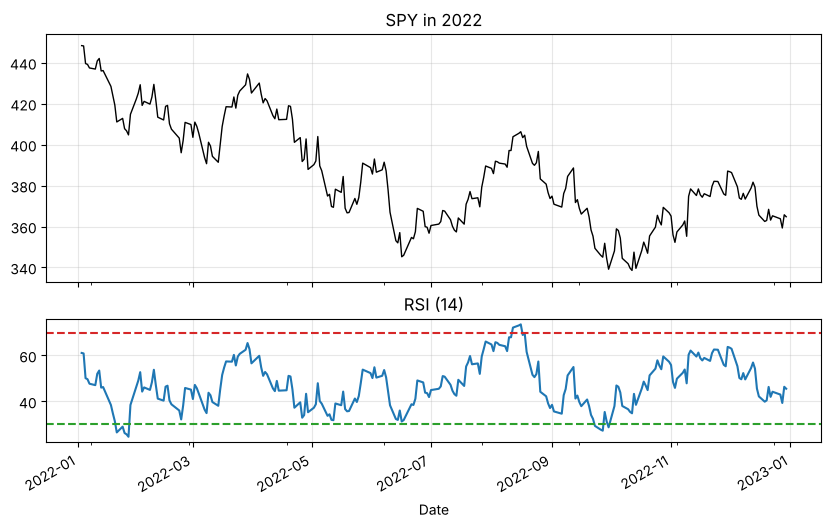

In [2]:
from backtester import load_prices, run_backtest
from backtester.plotting import plot_signals
from strategies import ma_crossover, rsi, rsi_mean_reversion

spy = load_prices("SPY")
spy_rsi = rsi(spy["Close"], period=14)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
spy["Close"].loc["2022"].plot(ax=top, color="black", linewidth=1, title="SPY in 2022")
spy_rsi.loc["2022"].plot(ax=bottom, title="RSI (14)")
bottom.axhline(30, linestyle="--", color="tab:green")
bottom.axhline(70, linestyle="--", color="tab:red")
top.grid(alpha=0.3); bottom.grid(alpha=0.3)
plt.show()

## Backtest it

`rsi_mean_reversion` turns the RSI into positions: `1` (hold SPY) from the day the RSI drops below 30 until the day it rises above 70, and `0` (cash) the rest of the time. `run_backtest` then trades those positions with the same $10,000 and 5 bps cost as notebook 04, and the summary compares the result with buy & hold.

In [3]:
positions = rsi_mean_reversion(spy, period=14, lower=30, upper=70)
result = run_backtest(spy, positions, cost_bps=5)
result.summary()

,Strategy,Buy & hold
Total return,98.8%,360.6%
Annual return (CAGR),6.6%,15.3%
Annual volatility,14.1%,17.7%
Sharpe ratio,0.52,0.89
Max drawdown,-28.3%,-33.7%
Number of trades,10,—
Win rate,90.0%,—


**Look at the win rate.** A high share of winning trades sounds wonderful, yet the total return is far below buy and hold's. Winning often is not the same as winning big: this strategy takes small profits quickly and then sits in cash while the market rises. And with only a handful of trades, a high win rate says little (notebook 02).

The same two charts as in notebook 04: portfolio value on top, drawdown underneath. Flat stretches in the strategy's line are days spent in cash, earning nothing but losing nothing either.

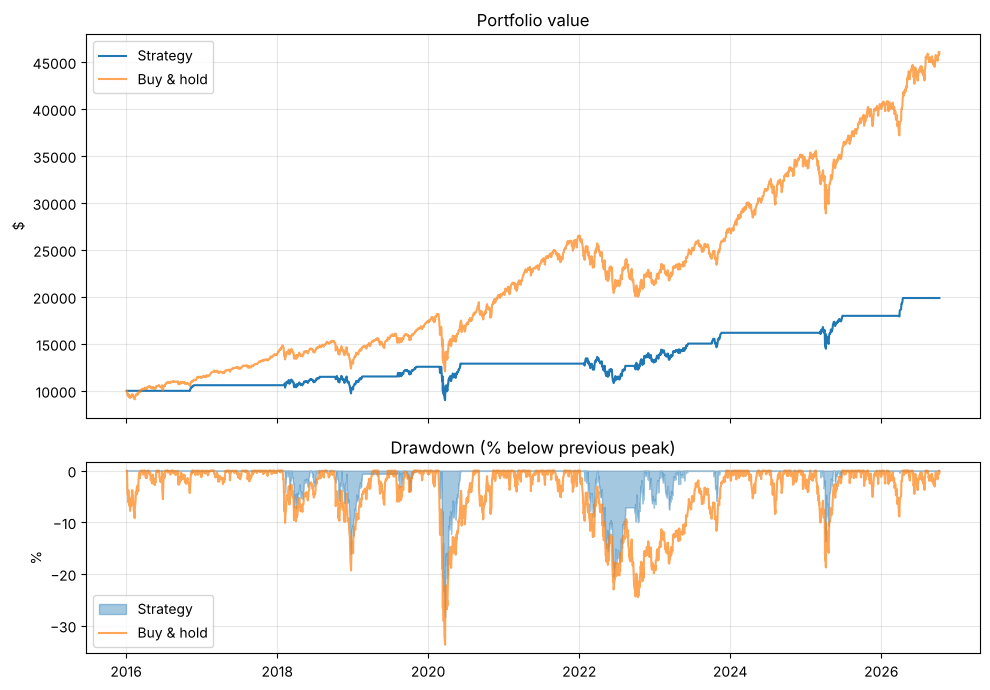

In [4]:
result.plot()

Where did it buy and sell? This chart marks every buy (green ▲) and sell (red ▼) on the SPY price. Buys should come after sharp drops and sells after strong rallies: the opposite of the crossover in notebook 04.

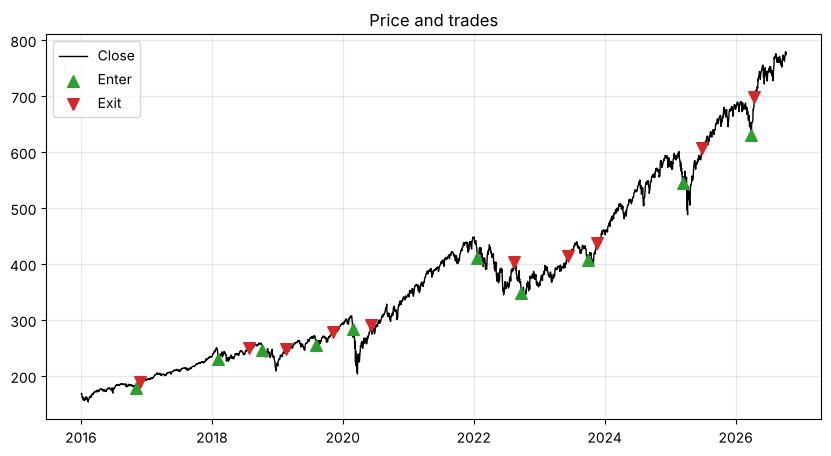

In [5]:
plot_signals(spy, result)

**✏️ Try it:** change `lower` and `upper` (e.g. 20/80 or 35/65). Do you trade more or less? What happens to the win rate?

## Trend following vs mean reversion

Neither style wins everywhere — trend following likes long, steady moves; mean reversion likes choppy, sideways markets. Let's compare both strategies (with default settings) on several tickers.

The cell below loops over eight tickers, backtests both strategies on each, and puts their Sharpe ratios next to buy & hold's. A higher Sharpe means more return for each unit of risk.

In [6]:
rows = []
for ticker in ["SPY", "QQQ", "IWM", "XLU", "XLE", "GLD", "TLT", "AAPL"]:
    prices = load_prices(ticker)
    ma = run_backtest(prices, ma_crossover(prices))
    rs = run_backtest(prices, rsi_mean_reversion(prices))
    rows.append({
        "Ticker": ticker,
        "Buy & hold Sharpe": ma.benchmark_metrics["Sharpe ratio"],
        "MA crossover Sharpe": ma.metrics["Sharpe ratio"],
        "RSI Sharpe": rs.metrics["Sharpe ratio"],
    })

table = pd.DataFrame(rows).set_index("Ticker").round(2).replace(-0.0, 0.0)
table

,Buy & hold Sharpe,MA crossover Sharpe,RSI Sharpe
Ticker,,,
SPY,0.89,0.75,0.52
QQQ,0.95,0.98,0.67
IWM,0.55,0.19,0.32
XLU,0.58,0.39,0.53
XLE,0.53,0.50,0.41
GLD,0.83,0.61,0.27
TLT,-0.01,0.00,-0.10
AAPL,1.00,0.71,0.77


**The straight answer.** The next cell counts, for each strategy, the tickers where its Sharpe ratio is higher than buy and hold's. Notebook 02 made buy and hold the benchmark, the bar to clear, so this is the score that counts.

In [7]:
pd.DataFrame({
    "tickers beaten (of 8)": {
        "MA crossover": int((table["MA crossover Sharpe"] > table["Buy & hold Sharpe"]).sum()),
        "RSI": int((table["RSI Sharpe"] > table["Buy & hold Sharpe"]).sum()),
    }
})

,tickers beaten (of 8)
MA crossover,2
RSI,0


At the time of writing, neither strategy beats buy and hold on more than a couple of the eight, and RSI beats it on none. This is the most common result in quant research: most simple rules lose to doing nothing once costs are charged. A strategy that fails this test is not a failure of the workshop. It is the workshop working.

The tickers where a strategy does well are worth a look: does the asset trend (a steady climb or fall, where the crossover helps) or chop sideways (where RSI helps)? Be careful, though. You are now looking at eight results and picking the best, which is exactly the trap from notebook 02.

**Questions to discuss:**
- On which tickers does each strategy do best? Do those assets trend or chop around?
- Does either strategy beat buy-and-hold consistently? (Be honest — this is the most common result in quant research!)
- How could you combine the two ideas? (One of the exercises in [`docs/resources.md`](https://github.com/aurvyl/qm-fintech-quant-workshop/blob/main/docs/resources.md).)

### Next: portfolios

So far every strategy held one asset, fully in or out. Portfolios hold many assets in chosen amounts.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aurvyl/qm-fintech-quant-workshop/blob/main/notebooks/06_portfolios.ipynb) `06_portfolios.ipynb`